# Exploratory analysis: KEV catalog and CVE records

I use this notebook to profile the inputs before trusting any metric: what each column holds, where values
are missing, which dates disagree, and how much each rule (launch backlog, CVSS precedence, vendor
normalization) changes the numbers. The pipeline in `src/kev_analytics/` is the source of truth; this is
where I looked at the data first.

Inputs: `data/sample/known_exploited_vulnerabilities.csv` (CISA KEV, CC0), `data/sample/cve_fields.csv`
(fields extracted from one CVE JSON 5.x record per entry) and the DuckDB file from
`python -m kev_analytics build`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from kev_analytics import analyze, baseline, clean, paths, warehouse

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 3.4), "axes.spines.top": False,
                     "axes.spines.right": False})
S1, S2 = "#2b9fd0", "#e0703a"
manifest = json.loads(paths.SNAPSHOT_MANIFEST.read_text())
{k: manifest["kev"][k] for k in ("catalog_version", "date_released", "retrieved_utc", "json_count")}

{'catalog_version': '2026.10.08',
 'date_released': '2026-10-08T20:09:18.9833Z',
 'retrieved_utc': '2026-10-11T19:43:04Z',
 'json_count': 1739}

## 1. Raw KEV snapshot: shape, types and missing values

In [2]:
raw = clean.read_kev_csv(paths.KEV_SNAPSHOT_CSV)
profile = pd.DataFrame({
    "non_empty": (raw != "").sum(),
    "distinct": raw.nunique(),
    "leading_or_trailing_space": raw.apply(lambda s: (s != s.str.strip()).sum()),
    "max_len": raw.apply(lambda s: s.str.len().max()),
})
print(raw.shape)
profile

(1739, 12)


,non_empty,distinct,leading_or_trailing_space,max_len
cveID,1739,1739,0,16
vendorProject,1739,288,6,32
product,1739,703,13,179
vulnerabilityName,1739,1393,27,161
dateAdded,1739,483,0,10
shortDescription,1739,1651,35,821
requiredAction,1739,46,2,520
dueDate,1739,506,0,10
knownRansomwareCampaignUse,1739,2,0,7
forensicTriage,1739,2,0,3


Every column is filled except `cwes`. Some text fields carry stray spaces (`vendorProject`, `product`,
`vulnerabilityName`), which matters for grouping, so staging trims them. `notes` is never empty: it holds
reference URLs and, for newer entries, links to BOD 26-04 guidance.

In [3]:
print("duplicate cveID:", raw["cveID"].duplicated().sum())
print(raw["knownRansomwareCampaignUse"].value_counts().to_dict())
print(raw["forensicTriage"].value_counts().to_dict())
cwe_counts = raw["cwes"].map(clean.parse_cwe_list).map(len)
print("CWEs per entry:", cwe_counts.value_counts().sort_index().to_dict())

duplicate cveID: 0
{'Unknown': 1378, 'Known': 361}
{'No': 1661, 'Yes': 78}
CWEs per entry: {0: 175, 1: 1457, 2: 100, 3: 6, 4: 1}


## 2. When were entries added? The launch batch

In [4]:
kev = clean.load_kev(paths.KEV_SNAPSHOT_CSV)
by_day = kev["date_added"].value_counts().sort_values(ascending=False)
print(by_day.head(8))
print("earliest dateAdded:", kev["date_added"].min().date())

date_added
2021-11-03    287
2022-03-03     95
2022-03-25     66
2022-06-08     35
2022-05-25     34
2022-03-28     32
2022-05-23     21
2022-05-24     20
Name: count, dtype: int64
earliest dateAdded: 2021-11-03


The single largest day is the catalog's first day, 2021-11-03, with 287 entries. These were not
newly exploited that day; CISA seeded the catalog with vulnerabilities already known to be exploited. Other
large days in early 2022 are also back-fill batches. My primary rule treats only the launch day as
backlog, because it is the one batch with an unambiguous definition, and section 6 shows what changes under
wider rules.

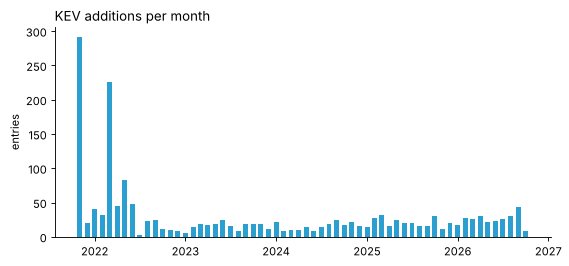

In [5]:
m = kev.set_index("date_added").resample("MS").size()
fig, ax = plt.subplots()
ax.bar(m.index, m.values, width=20, color=S1)
ax.set_title("KEV additions per month", loc="left")
ax.set_ylabel("entries")
plt.show()

## 3. CVE records: coverage and the date fields

In [6]:
cve = pd.read_csv(paths.CVE_FIELDS_CSV, dtype=str, keep_default_na=False).replace("", np.nan)
print(cve["fetch_status"].value_counts().to_dict(), cve["record_state"].value_counts().to_dict())
print(cve["data_version"].value_counts().to_dict())
cve[["date_reserved", "date_published", "cna_date_public"]].notna().sum()

{'ok': 1739} {'PUBLISHED': 1739}
{'5.1': 998, '5.2': 741}


date_reserved      1739
date_published     1739
cna_date_public     816
dtype: int64

All KEV CVE IDs resolved to a PUBLISHED record (no rejected or missing records in this snapshot; the
pipeline would keep and flag them). `cna_date_public`, the CNA's own disclosure date, is present for fewer
than half the records, so it can only be a sensitivity check, not the main date.

The cvelistV5 README warns that published and updated dates are inconsistent for some older records, and
notes a 2024 correction of about 27,000 pre-2023 records and a February 2026 date normalization. I test the
dates against each other below.

In [7]:
f = analyze.build_fact(kev, cve)
f["reserved_utc"] = clean.utc_date(f["date_reserved"])
checks = {
    "published before reserved": int((f["date_published_utc"] < f["reserved_utc"]).sum()),
    "published year before ID year": int((f["published_year"] < f["cve_id_year"]).sum()),
    "published 2+ years after ID year": int((f["published_year"] > f["cve_id_year"] + 1).sum()),
    "KEV before CVE publication": int((f["lag_days"] < 0).sum()),
    "KEV 30+ days before publication": int((f["lag_days"] < -30).sum()),
}
checks

{'published before reserved': 0,
 'published year before ID year': 0,
 'published 2+ years after ID year': 19,
 'KEV before CVE publication': 61,
 'KEV 30+ days before publication': 16}

In [8]:
cols = ["cve_id", "vendor", "assigner_short_name", "date_published", "cna_date_public", "date_added", "lag_days"]
f.loc[f["lag_days"] < -30, cols].sort_values("lag_days")

,cve_id,vendor,assigner_short_name,date_published,cna_date_public,date_added,lag_days
1250,CVE-2022-26486,Mozilla,mozilla,2022-12-22T00:00:00.000Z,NaN,2022-03-07,-290
1251,CVE-2022-26485,Mozilla,mozilla,2022-12-22T00:00:00.000Z,NaN,2022-03-07,-290
1071,CVE-2019-8720,WebKitGTK,redhat,2023-03-06T00:00:00.000Z,NaN,2022-05-23,-287
1137,CVE-2022-1096,Google,Chrome,2022-07-22T23:35:35.000Z,NaN,2022-03-28,-116
1096,CVE-2022-1364,Google,Chrome,2022-07-26T21:30:44.000Z,NaN,2022-04-15,-102
1429,CVE-2021-4102,Google,Chrome,2022-02-11T22:55:22.000Z,NaN,2021-12-15,-58
765,CVE-2023-38205,Adobe,adobe,2023-09-14T07:40:12.725Z,2023-07-19T17:00:00.000Z,2023-07-20,-56
1127,CVE-2022-22675,Apple,apple,2022-05-26T17:44:27.000Z,NaN,2022-04-04,-52
1128,CVE-2022-22674,Apple,apple,2022-05-26T17:43:37.000Z,NaN,2022-04-04,-52
1388,CVE-2022-22587,Apple,apple,2022-03-18T17:59:15.000Z,NaN,2022-01-28,-49


These are CVE records that entered the CVE List weeks or months after CISA had already listed the ID.
Apple, Google Chrome and Mozilla records make up 14 of the 16. Only one of the 16 has a CNA `datePublic`
(the Adobe record, one day before the KEV date). I cannot check vendor advisory dates from this environment,
but the pattern (browser and OS vendors, record published long after listing) fits records being filed late
rather than KEV dates being wrong. So `datePublished` measures when the *CVE record* went public, which for
some CNAs trails disclosure. I keep it as the primary clock (it exists for every record) and report the
disclosure-date variant, earliest of `datePublished` and `datePublic`, as a sensitivity check.

In [9]:
dp = f.dropna(subset=["cna_date_public_utc"])
diff = (dp["date_published_utc"] - dp["cna_date_public_utc"]).dt.days
print(diff.describe().round(1))
print("records where datePublic is more than 30 days before datePublished:", int((diff > 30).sum()))

count     816.0
mean       12.2
std       151.5
min     -2963.0
25%         0.0
50%         1.0
75%         3.0
max      2324.0
dtype: float64
records where datePublic is more than 30 days before datePublished: 40


## 4. The lag: distribution and shape

count    1452.0
mean      917.1
std      1327.7
min      -290.0
10%         0.0
25%         4.0
50%       166.5
75%      1514.2
90%      2842.0
max      6910.0
Name: lag_days, dtype: float64


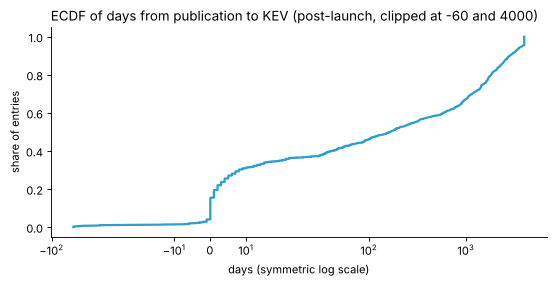

In [10]:
post = f[~f["is_launch_backlog"] & f["lag_days"].notna()]
lag = post["lag_days"].astype(float)
print(lag.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
fig, ax = plt.subplots()
x = np.sort(lag.clip(-60, 4000))
ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=S1, lw=2)
ax.set_xscale("symlog", linthresh=30)
ax.set_title("ECDF of days from publication to KEV (post-launch, clipped at -60 and 4000)", loc="left")
ax.set_xlabel("days (symmetric log scale)")
ax.set_ylabel("share of entries")
plt.show()

The ECDF climbs steeply in the first week and then flattens; another rise comes years out. The mean is
pulled far above the median by old CVEs, so I report medians, quartiles and threshold shares, never the mean.

In [11]:
pd.DataFrame({
    "within 0 days": [(lag <= 0).mean()], "within 7": [(lag <= 7).mean()],
    "within 30": [(lag <= 30).mean()], "within 365": [(lag <= 365).mean()],
}).round(3)

,within 0 days,within 7,within 30,within 365
0,0.155,0.293,0.374,0.57


## 5. Two views over time: by year added and by publication year

In [12]:
by_added = f.groupby("added_year")["lag_days"].agg(
    entries="size", median="median",
    within_30=lambda s: (s <= 30).mean(), over_1y=lambda s: (s > 365).mean()).round(3)
by_added

,entries,median,within_30,over_1y
added_year,,,,
2021,311,446.0,0.064,0.556
2022,555,1436.0,0.123,0.753
2023,187,12.0,0.551,0.246
2024,186,21.5,0.511,0.242
2025,245,26.0,0.514,0.229
2026,255,15.0,0.561,0.196


In [13]:
by_pub = post.groupby("published_year")["lag_days"].agg(
    entries="size", median="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75),
    within_30=lambda s: (s <= 30).mean())
by_pub.loc[2016:].round(2)

,entries,median,p25,p75,within_30
published_year,,,,,
2016,43,2122.0,2046.0,2263.5,0.0
2017,77,1756.0,1685.0,1880.0,0.0
2018,62,1436.0,1367.5,1482.5,0.0
2019,88,1032.0,920.5,1162.25,0.0
2020,53,751.0,624.0,1401.0,0.0
2021,104,371.0,194.0,942.5,0.06
2022,131,24.0,0.0,167.0,0.52
2023,166,6.0,0.0,104.75,0.64
2024,160,11.0,1.0,107.0,0.59


The publication-year view needs care. A CVE published in 2025 has had at most about 21 months to be
listed, while one published in 2016 has had ten years. Old cohorts can only contain long lags (anything they
had that was listed fast happened before KEV existed), and recent cohorts can only contain short ones so far.
So medians by publication year fall over time partly by construction. The year-added view does not have that
problem, and it shows the change I trust more: since 2023 roughly half of each year's additions were
published within the previous 30 days.

In [14]:
cc = warehouse.query("SELECT * FROM analytics.cohort_cumulative")
cc.pivot(index="published_year", columns="years_since_pub", values="cumulative_entries")

years_since_pub,0,1,2,3,4,5
published_year,,,,,,
2021,162.0,179.0,196.0,203.0,213.0,215.0
2022,112.0,119.0,127.0,129.0,131.0,NaN
2023,145.0,156.0,163.0,166.0,NaN,NaN
2024,149.0,157.0,160.0,NaN,NaN,NaN
2025,192.0,197.0,NaN,NaN,NaN,NaN
2026,178.0,NaN,NaN,NaN,NaN,NaN


Within each publication cohort since 2021 most entries arrive in the first year after publication, and later
years add a thin tail. That tail is what right-censoring hides from the recent cohorts.

## 6. Sensitivity of the headline to the backlog rule and the clock

In [15]:
warehouse.query("SELECT * FROM analytics.lag_sensitivity").round(3)

,rule,entries,median_lag_days,p25_lag_days,p75_lag_days,share_within_30d
0,Primary: exclude launch-day batch,1452,166.5,4.0,1514.25,0.374
1,All entries,1739,246.0,8.0,1365.00,0.319
2,Exclude six-month remediation window (older-CV...,1482,120.0,4.0,1321.00,0.374
3,Exclude everything added before 2023,873,18.0,1.0,264.00,0.535
4,"Primary, measured from disclosure (earliest of...",1452,166.5,4.0,1520.00,0.372


The median moves a lot with the inclusion rule (it is a bimodal distribution, so the median sits in the
gap between the modes), while the share listed within 30 days of publication barely moves between the
launch-day rule and the six-month-window rule. That is why the summary leads with shares rather than the
median.

## 7. CVSS: which score is in the record?

In [16]:
print(cve["cvss_source"].value_counts(dropna=False).to_dict())
print(cve["cvss_version"].value_counts(dropna=False).to_dict())
pd.crosstab(cve["cvss_severity"], cve["cna_cvss_severity"], margins=True)

{'adp': 990, 'cna': 749}
{'3.1': 1605, '4.0': 74, '3.0': 60}


cna_cvss_severity,Critical,High,Low,Medium,No CVSS in record,All
cvss_severity,,,,,,
Critical,309,0,0,0,303,612
High,0,334,0,0,582,916
Low,0,0,5,0,4,9
Medium,0,0,0,101,101,202
All,309,334,5,101,990,1739


More than half of the entries have no CVSS score from their CNA at all; CISA's ADP container ("Vulnrichment")
supplies one for every one of those. That matters for any comparison with CVEs in general, because CISA
enriches KEV entries on purpose. For the comparison with the random baseline I therefore use CNA scores
only, on both sides.

In [17]:
base = baseline.load()
pub = base[base["record_state"] == "PUBLISHED"]
print(base["record_state"].value_counts().to_dict())
print(pub.groupby("id_year").size().to_dict())
(pd.crosstab(pub["id_year"], pub["cna_cvss_severity"], normalize="index") * 100).round(1)

{'PUBLISHED': 3340, 'NO_RECORD': 2556, 'REJECTED': 104}
{2021: 556, 2022: 604, 2023: 655, 2024: 792, 2025: 733}


cna_cvss_severity,Critical,High,Low,Medium,No CVSS in record,None
id_year,,,,,,
2021,4.5,16.0,3.6,17.8,58.1,0.0
2022,4.3,14.9,3.5,21.9,55.5,0.0
2023,4.7,23.2,3.8,32.1,36.2,0.0
2024,5.1,26.5,4.4,35.1,28.9,0.0
2025,5.6,34.0,5.6,34.7,20.1,0.1


The baseline is a simple random sample of ID numbers within each ID year (see `baseline.py`). Hit rates
differ by year because ID blocks are reserved and not all used. The share without any CNA score falls over
time as more CNAs score their own records.

In [18]:
sev = pd.read_csv(paths.OUTPUTS_DIR / "severity_vs_baseline_bootstrap.csv", keep_default_na=False, na_values=[""])
sev[["band", "kev_entries", "kev_share", "baseline_share", "est_population", "kev_rate", "kev_rate_lo", "kev_rate_hi"]].round(4)

,band,kev_entries,kev_share,baseline_share,est_population,kev_rate,kev_rate_lo,kev_rate_hi
0,Critical,199,0.2298,0.0488,7974.0308,0.0250,0.0216,0.0292
1,High,250,0.2887,0.2365,39691.0083,0.0063,0.0059,0.0067
2,Medium,76,0.0878,0.2913,48212.5225,0.0016,0.0015,0.0017
3,Low,5,0.0058,0.0425,7036.5483,0.0007,0.0006,0.0008
4,None,0,0.0000,0.0003,59.9992,0.0000,0.0000,NaN
5,No CVSS in record,336,0.3880,0.3805,58377.2742,0.0058,0.0055,0.0060


This is a rate among CVEs in the frame (ID years 2021-2025) that ended up in KEV by the snapshot date, by the
CNA's severity band. It is an association. KEV listing depends on CISA observing exploitation, and more
severe bugs may get more attention from both attackers and defenders.

## 8. Vendors, ransomware and CWEs

In [19]:
vm = warehouse.query("SELECT * FROM model.vendor_map WHERE rule <> 'unchanged'")
vm

,vendor_raw,vendor_clean,vendor,rule,reason
0,Zammad GmbH,Zammad GmbH,Zammad,legal_suffix,NaN
1,Array Networks,Array Networks,Array Networks,whitespace,NaN
2,PHP Group,PHP Group,PHP,alias,Same project. KEV lists PHP itself under both ...
3,QNAP Systems,QNAP Systems,QNAP,alias,"Same company (QNAP Systems, Inc.)."
4,Soliton Systems K.K,Soliton Systems K.K,Soliton Systems,legal_suffix,NaN
5,SimpleHelp,SimpleHelp,SimpleHelp,whitespace,NaN
6,Meta Platforms,Meta Platforms,Meta,alias,Same company. KEV uses both labels (WhatsApp e...
7,VMware Tanzu,VMware Tanzu,VMware,alias,Tanzu is a VMware product line (Spring entries...


In [20]:
vs = warehouse.query("SELECT vendor, entries, share_of_entries, cumulative_share, ransomware_share, recent_24m_entries FROM analytics.vendor_summary")
vs.head(12).round(3)

,vendor,entries,share_of_entries,cumulative_share,ransomware_share,recent_24m_entries
0,Microsoft,389,0.224,0.224,0.301,86
1,Cisco,100,0.058,0.281,0.070,28
2,Apple,95,0.055,0.336,0.000,20
3,Adobe,82,0.047,0.383,0.134,10
4,Google,75,0.043,0.426,0.000,15
5,Oracle,46,0.026,0.453,0.283,10
6,Apache,41,0.024,0.476,0.195,6
7,Ivanti,35,0.020,0.496,0.343,14
8,Fortinet,31,0.018,0.514,0.452,18
9,Linux,31,0.018,0.532,0.065,15


In [21]:
cw = warehouse.query("SELECT cwe_id, cwe_name, cwe_family, entries, weighted_entries, ransomware_share FROM analytics.cwe_summary")
print("entries with more than one CWE:", int((f.merge(clean.cwe_bridge(kev, cve).groupby('cve_id').size().rename('n'), left_on='cve_id', right_index=True)['n'] > 1).sum()))
cw.head(12).round(3)

entries with more than one CWE: 109


,cwe_id,cwe_name,cwe_family,entries,weighted_entries,ransomware_share
0,CWE-20,Improper Input Validation,Input validation (generic),127,112.000,0.220
1,CWE-78,Improper Neutralization of Special Elements us...,Injection,110,101.917,0.109
2,CWE-unknown,No CWE recorded,Unknown (no CWE recorded),109,109.000,0.239
3,CWE-787,Out-of-bounds Write,Memory safety,106,97.500,0.151
4,CWE-416,Use After Free,Memory safety,96,94.500,0.104
5,CWE-119,Improper Restriction of Operations within the ...,Memory safety,93,92.500,0.097
6,CWE-22,Improper Limitation of a Pathname to a Restric...,Path traversal and file handling,81,77.500,0.333
7,CWE-94,Improper Control of Generation of Code ('Code ...,Injection,76,72.333,0.158
8,CWE-502,Deserialization of Untrusted Data,Deserialization,74,69.333,0.405
9,CWE-287,Improper Authentication,Authentication and access control,49,45.083,0.347


Counting a multi-CWE entry under each of its CWEs is correct for "how many entries involve CWE-X", but
summing those counts across CWEs would exceed the number of entries. The bridge carries a weight of 1/n per
entry so totals add back to the catalog; `04_validation.sql` fails the build if they do not.

## 9. Remediation windows

In [22]:
rw = (kev["due_date"] - kev["date_added"]).dt.days
pd.crosstab(kev["date_added"].dt.year, rw.where(rw.isin([3, 7, 14, 21, 181]), other=-1).replace(-1, "other"))

col_0,3,7,14,21,181,other
date_added,,,,,,
2021,0,0,111,0,189,11
2022,0,0,88,403,49,15
2023,0,1,0,177,0,9
2024,0,7,0,175,0,4
2025,0,12,0,226,0,7
2026,130,0,78,44,0,3


The data shows three regimes. In the launch period, about six months (181-184 days) for older CVEs and
14 days for recent ones; 21 days as the norm from 2022 to 2025; and in 2026 a move to 14 days and then
3 days, with a new `forensicTriage` flag. I could not fetch the directive text from this environment, so the docs describe the windows only.

## What I took from this

* The lag is bimodal, so medians alone mislead; I report threshold shares and quartiles with the median.
* The launch-day rule is simple and testable; wider backlog rules change the median but not the 30-day share.
* `datePublished` is a record date, not always the disclosure date; I keep it and show the alternative.
* CNA-only severity is the fair basis for comparing KEV with CVEs in general because CISA enriches KEV entries.
* Vendor names needed only eight changes, each listed in `model.vendor_map`.